<p style="font-weight: bold; text-transform: uppercase; letter-spacing: 1.2px; color: #666666; margin-bottom: 4px;">
    Python para Ciencia de Datos
</p>

# Impacto de las redes sociales en el bienestar psicológico y educativo de los jóvenes
### Análisis descriptivo y modelado

<br>

**Hecho por Santiago Robatto y Lucas Giúdice**  
Octubre 2026

**Link:** https://www.kaggle.com/datasets/harishyadav0506/impact-of-social-media-on-life (redes sociales)

In [134]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import squarify

In [135]:
# Estética global para todo el informe
plt.style.use(
    "seaborn-v0_8-whitegrid"
    if "seaborn-v0_8-whitegrid" in plt.style.available
    else "default"
)

# Parámetros globales 
plt.rcParams.update({
    # Márgenes y bordes exteriores de los gráficos
    "axes.edgecolor": "#cccccc",
    "axes.linewidth": 0.8,
    "axes.spines.top": True,
    "axes.spines.right": True,
    "axes.spines.bottom": True,
    "axes.spines.left": True,
    # Estilo de las fuentes y títulos
    "font.family": "sans-serif",
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlepad": 12,
    "axes.labelsize": 10,
    # Estilo de la grilla interna por defecto
    "grid.linestyle": ":",
    "grid.alpha": 0.6,
})

In [136]:
# Cargamos los datos
datos = pd.read_csv("Datos/Entrada/Social_media_impact_on_life.csv")

# Generamos un respaldo
redes = datos

# Introducción

La consolidación de las redes sociales como una dimensión central de la cotidianeidad es un fenómeno innegable en la actualidad. Su crecimiento exponencial en las últimas décadas ha reconfigurado sustancialmente las dinámicas de comunicación, sociabilidad y acceso a la información, fenómeno que se agudiza especialmente en la población más joven. 

Si bien estas plataformas ofrecen oportunidades para el aprendizaje colaborativo, la libre expresión y la interacción con pares, también plantean complejos desafíos vinculados al rendimiento académico, a la salud mental y el bienestar socioemocional de los estudiantes. 

En este escenario, resulta relevante generar evidencia empírica que permita evaluar de manera objetiva el impacto real de las redes sociales en la salud mental y la trayectoria educativa de los jóvenes.

 El interés es el de evaluar el impacto que las redes sociales pueden tener cuando se utilizan de manera intensiva. El impacto se mide en disintos aspectos de la vida de los encuestados.  Para realizar un análisis integral y abarcativo de esta nueva realidad decidió trabajar con todas las variables. Únicamente se omite el uso de la variable identificadora, dado que la misma no aporta información relevante. 

## Estructura de los datos

Se utiliza el dataset **Impact of Social Media on Life**, publicado por Harish Yadav en Kaggle, cuyo link se adjunta en el inicio del informe. 

La base contiene **4.500 registros y 16 columnas: 15 variables y un identificador**. Las edades observadas van de 15 a 26 años, con estudiantes de secundaria, universidad y posgrado.





In [137]:
diccionario = pd.DataFrame([
    {
        "Variable": "Age",
        "Tipo": "Integer",
        "Descripción": "Edad",
    },
    {
        "Variable": "Gender",
        "Tipo": "String",
        "Descripción": "Género",
    },
    {
        "Variable": "Academic_Level",
        "Tipo": "String",
        "Descripción": "Nivel académico",
    },
    {
        "Variable": "Primary_Platform",
        "Tipo": "String",
        "Descripción": "Principal red social",
    },
    {
        "Variable": "Daily_Usage_Hours",
        "Tipo": "Float",
        "Descripción": "Uso promedio diario en horas",
    },
    {
        "Variable": "Weekend_Extra_Hours",
        "Tipo": "Float",
        "Descripción": "Cantidad de horas de consumo en el fin de semana",
    },
    {
        "Variable": "Device_Type",
        "Tipo": "String",
        "Descripción": "Dispositivo de acceso principal",
    },
    {
        "Variable": "Sleep_Duration_Hours",
        "Tipo": "Float",
        "Descripción": "Promedio de horas de sueño",
    },
    {
        "Variable": "Sleep_Quality_Score",
        "Tipo": "Integer",
        "Descripción": "Calidad del sueño (autoseleccionado)",
    },
    {
        "Variable": "Late_Night_Usage",
        "Tipo": "Boolean",
        "Descripción": "¿Uso nocturno (post media noche)?",
    },
    {
        "Variable": "Social_Comparison_Frequency",
        "Tipo": "Categorical",
        "Descripción": "Frequency of social comparison behaviors",
    },
    {
        "Variable": "Perceived_Stress_Score",
        "Tipo": "Float",
        "Descripción": "Indicador de estrés (entre 1 y 40)",
    },
    {
        "Variable": "Mental_Health_Index",
        "Tipo": "Integer",
        "Descripción": "Indicador de salud mental (10 to 98)",
    },
    {
        "Variable": "Academic_Performance_GPA",
        "Tipo": "Float",
        "Descripción": "Promedio de calificaciones (Scale: 1.70 to 4.00)",
    },
    {
        "Variable": "Overall_Impact",
        "Tipo": "Categorical",
        "Descripción": "Variable de clasificación",
    },
])

(
    diccionario.style.set_caption("Diccionario de variables")
    .set_properties(**{"text-align": "left", "padding": "6px 12px"})
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#2c3e50"),
                ("color", "white"),
                ("font-weight", "bold"),
                ("text-align", "left"),
            ],
        },
        {"selector": "tr:nth-child(even)", "props": [("background-color", "#f9f9f9")]},
        {"selector": "tr:hover", "props": [("background-color", "#f1f1f1")]},
    ])
    .hide(axis="index")
)

Variable,Tipo,Descripción
Age,Integer,Edad
Gender,String,Género
Academic_Level,String,Nivel académico
Primary_Platform,String,Principal red social
Daily_Usage_Hours,Float,Uso promedio diario en horas
Weekend_Extra_Hours,Float,Cantidad de horas de consumo en el fin de semana
Device_Type,String,Dispositivo de acceso principal
Sleep_Duration_Hours,Float,Promedio de horas de sueño
Sleep_Quality_Score,Integer,Calidad del sueño (autoseleccionado)
Late_Night_Usage,Boolean,¿Uso nocturno (post media noche)?


In [138]:
# Reodificamos algunas variables categóricas

# Nivel educativo
redes["Academic_Level"] = redes["Academic_Level"].map({
    "High School": "Secundaria",
    "Undergraduate": "Universitario",
    "Postgraduate": "Posgrado"
})

# Género
redes["Gender"] = redes["Gender"].map({
    "Female": "Mujer",
    "Male": "Hombre",
    "Non-Binary": "No binario",
    "Prefer not to say": "No declara"
})

# Uso del celular en la noche
redes["Late_Night_Usage"] = redes["Late_Night_Usage"].map({
    True: "Si",
    False: "No"
})

# Ordenamos algunas variables categóricas

# Nivel educativo
redes["Academic_Level"] = pd.Categorical(
    redes["Academic_Level"],
    categories=["Secundaria", "Universitario", "Posgrado"],
    ordered=True
)

# Género
redes["Gender"] = pd.Categorical(
    redes["Gender"],
    categories=["Mujer", "Hombre", "No binario", "No declara"],
    ordered=True
)

## Análisis exploratorio

Con el fin de tener una impresión global sobre relaciones uno-a-uno de las variables numéricas disponibles, se genera un mapa de calor con el coeficiente de la correlación lineal de Pearson para cada cruce posible. 

Como primera noción, destaca la correlación definidamente negativa de la variable "Uso diario" con el resto de variables, con la única excepción del "Score de estrés". Esto nos indica que a mayor uso de las redes sociales se espera que tanto la calidad y duración del sueño, así como el promedio académico o el "Índice de salud mental" del estudiante tomen valores más pobres. Por otro lado, la correlación positiva no nos da tampoco noticias positivas, estando relacionado un estrés más alto a quienes las utilizan con mayor holgura.

El dato es concluyente: las redes sociales tienen correlaciones negativas no siempre percibidas. Sin embargo, sería poco prudente afirmar causalidad en este momento inicial del análisis. Habría que contemplar otros factores, por ejemplo la carga estudiantil, si el usuario trabaja o no, entre otros factores no medidos. 

Asimismo se visualiza como la calidad y la duración del sueño tienen correlación positiva con los indicadores de rendimiento ya sea académico: "Rendimiento académico", como psicológico; "Índice de salud mental" y "Score de estrés". 

Por último, existe correlación positiva entre estos dos ámbitos performáticos; entre lo mental y lo referente al saber. Es decir, uno no espera tener buenos rendimientos académicos en condiciones de alto estrés o en momentos de baja calidad de la salud mental propia. Como humanos somos un todo, por lo que es de esperar que estando en etapas donde psciológicamente u emocionalmente uno se siente más abrumado o vulnerable, exista un impacto en el rendimiento académico que no tenga explicitamente que ver con las capacidades o conocimientos propios.

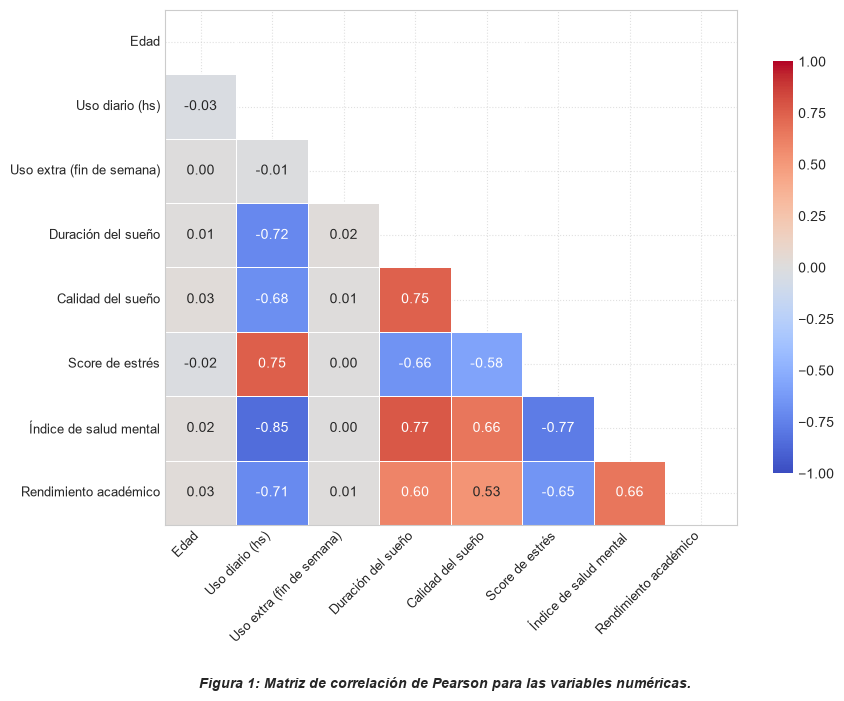

In [139]:
# Ponemos los nombres en español
nombres = {
    "Age": "Edad",
    "Daily_Usage_Hours": "Uso diario (hs)",
    "Weekend_Extra_Hours": "Uso extra (fin de semana)",
    "Sleep_Duration_Hours": "Duración del sueño",
    "Sleep_Quality_Score": "Calidad del sueño",
    "Perceived_Stress_Score": "Score de estrés",
    "Mental_Health_Index": "Índice de salud mental",
    "Academic_Performance_GPA": "Rendimiento académico",
}

# Seleccionar solo las columnas disponibles y renombrarlas
corr_base = redes.select_dtypes(include="number").rename(columns=nombres)

# Matriz de correlación
corr = corr_base.corr()

# Quiero unicamente la triangular inferior dado que es simétrica
fig, ax = plt.subplots(figsize=(9, 7))
mask = np.triu(np.ones_like(corr, dtype=bool))

# Heatmap
sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmax=1.0,
    vmin=-1.0,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"shrink": 0.8},
    ax=ax,
)

# Cuadro que lo enmarque acorde al resto de gráficos
for spine in ax.spines.values():
  spine.set_visible(True)
  spine.set_linewidth(0.8)
  spine.set_edgecolor("#cccccc")

# Etiqueta para el informe
fig.text(
    0.5,
    0.01,
    "Figura 1: Matriz de correlación de Pearson para las variables numéricas.",
    ha="center",
    fontsize=10,
    style="italic",
    weight="semibold",
)

plt.xticks(rotation=45, ha="right", fontsize=9)
plt.yticks(rotation=0, fontsize=9)

# Ajustar diseño dejando espacio abajo para el texto
plt.tight_layout(rect=[0, 0.05, 1, 1])

plt.show()

**Se continúa el estudio realizando un análisis univariado de las principales variables cuantitativas que posee el dataset.**

Se comienza con las distribuciones del promedio de uso diario de las redes sociales y la media de duración de sueño. Se obtienen comportamientos contrastantes entre ambas variables: mientras que el uso diario de redes presenta una marcada asimetría positiva con un sesgo hacia la derecha; la mediana (de 4.7 horas) se ubica por debajo de la media (de 5.3 horas), la segunda variable exhibe un patrón mucho más simétrico y equilibrado. Este suceso es causa de un grupo minoritario de consumos extremos que se extienden hasta las 14 horas en la variable de uso diario, lo cual eleva el resultado de la media. Respecto a la distribución del sueño, tanto la media (6.7 horas) como la mediana (6.8 horas) coinciden prácticamente en el centro, lo que evidencia que la mayor parte de la muestra se concentra de forma homogénea en torno a esos valores. Esto guarda sentido con la realidad, donde la distribución de sueños, más en un grupo tan contenido como el de los estudiantes se concentra en torno a valores de 6-9 horas. Se realizaron visualizaciones para discriminar según género o nivel académico del estudiante, pero no se observan diferencias concluyentes en las distribuciones de alguna de las variables.

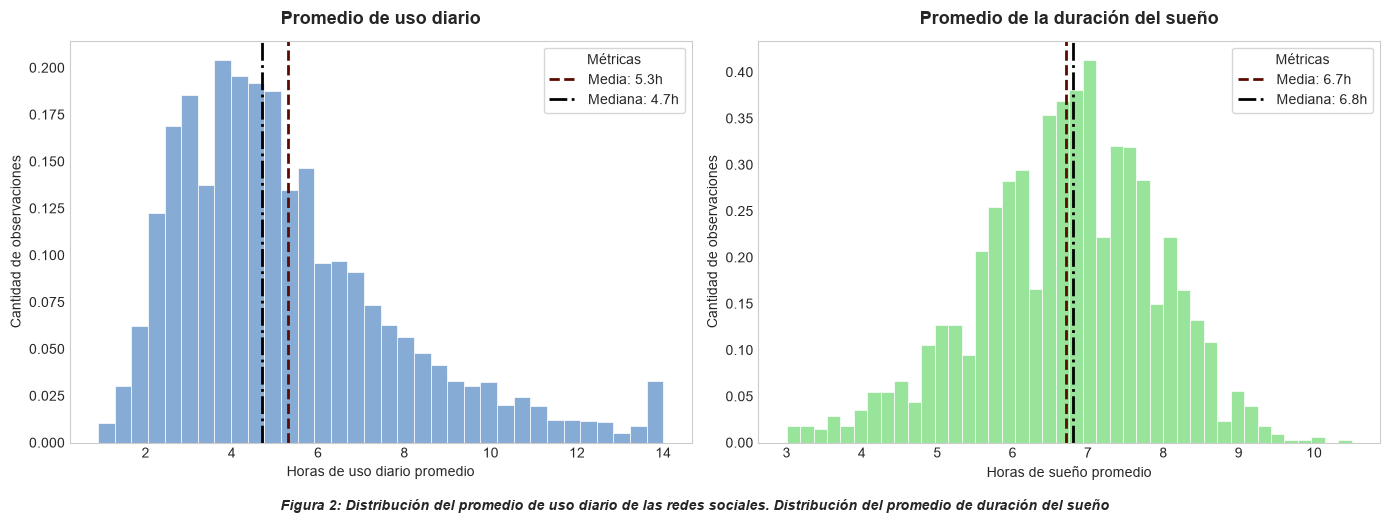

In [140]:
# Dos gráficos seguidos: Uso diario y Sueño
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Media y mediana del uso 
media_uso = redes["Daily_Usage_Hours"].mean()
mediana_uso = redes["Daily_Usage_Hours"].median()

# Media y mediana del sueño
media_sueño = redes["Sleep_Duration_Hours"].mean()
mediana_sueño = redes["Sleep_Duration_Hours"].median()

# Graficamos de uso
sns.histplot(
    data= redes,
    x="Daily_Usage_Hours",
    ax=ax1,
    color="#5d90c7",  
    edgecolor="white",
    stat = "density", # Para tener la densidad y no los conteos
    linewidth=0.5,
)

# Línea para la media
ax1.axvline(
    media_uso,
    color="#5c0a00",
    linestyle="--",
    linewidth=2,
    label=f"Media: {media_uso:.1f}h",
)

# Línea para la mediana
ax1.axvline(
    mediana_uso,
    color="#000000",
    linestyle="-.",
    linewidth=2,
    label=f"Mediana: {mediana_uso:.1f}h",
)

ax1.set_title("Promedio de uso diario")
ax1.set_xlabel("Horas de uso diario promedio")
ax1.set_ylabel("Cantidad de observaciones")
ax1.legend(title= "Métricas", frameon= True, loc= "upper right")
ax1.grid(False)


# Grafico de sueño
sns.histplot(
    data= redes,
    x="Sleep_Duration_Hours",
    ax=ax2,
    color="#76dc7a", 
    edgecolor="white",
    linewidth=0.5,
    stat = "density", # Para tener la densidad y no los conteos
)

# Agregar líneas verticales para la Media y la Mediana
ax2.axvline(
    media_sueño,
    color="#5c0a00",
    linestyle="--",
    linewidth=2,
    label=f"Media: {media_sueño:.1f}h",
)
ax2.axvline(
    mediana_sueño,
    color="#000000",
    linestyle="-.",
    linewidth=2,
    label=f"Mediana: {mediana_sueño:.1f}h",
)

ax2.set_title("Promedio de la duración del sueño")
ax2.set_xlabel("Horas de sueño promedio")
ax2.set_ylabel("Cantidad de observaciones")
ax2.legend(title="Métricas", frameon=True, loc="upper right")
ax2.grid(False)

# Etiqueta para el informe
fig.text(
    0.5,
    -0.03,
    "Figura 2: Distribución del promedio de uso diario de las redes sociales. Distribución del promedio de duración del sueño",
    ha="center",
    fontsize=10,
    style="italic",
    weight="semibold",
)

# Mostrar ambos gráficos ordenados
plt.tight_layout()
plt.show()

Por otra parte, se visualizan las variables que nos indican el estado psicológico del encuestado, así como su rendimiento académico. En primer lugar, el score de estrés presenta una distribución moderadamente centrada con una ligera dispersión hacia valores elevados que denota la presencia de minorías bajo mayor tensión. En contraste, el índice de salud mental y el rendimiento académico muestran patrones con un marcado sesgo hacia los valores superiores. En estos últimos casos, la gran mayoría de las observaciones se concentra densamente en los rangos más altos, evidenciando niveles favorables de bienestar general y un desempeño académico consistentemente alto en la mayor parte de la muestra. En conjunto, este comportamiento global refleja que, a pesar de las tensiones específicas que experimentan ciertos sectores, la comunidad estudiantil preserva un equilibrio general sólido que nos da buenas noticias sobre el estado general de bienestar y éxito académico de los estudiantes. Se realizó la correspondiente disgregación por género o nivel educativo, donde nuevamente las distribuciones obtenidas no generaron resultados disimiles.

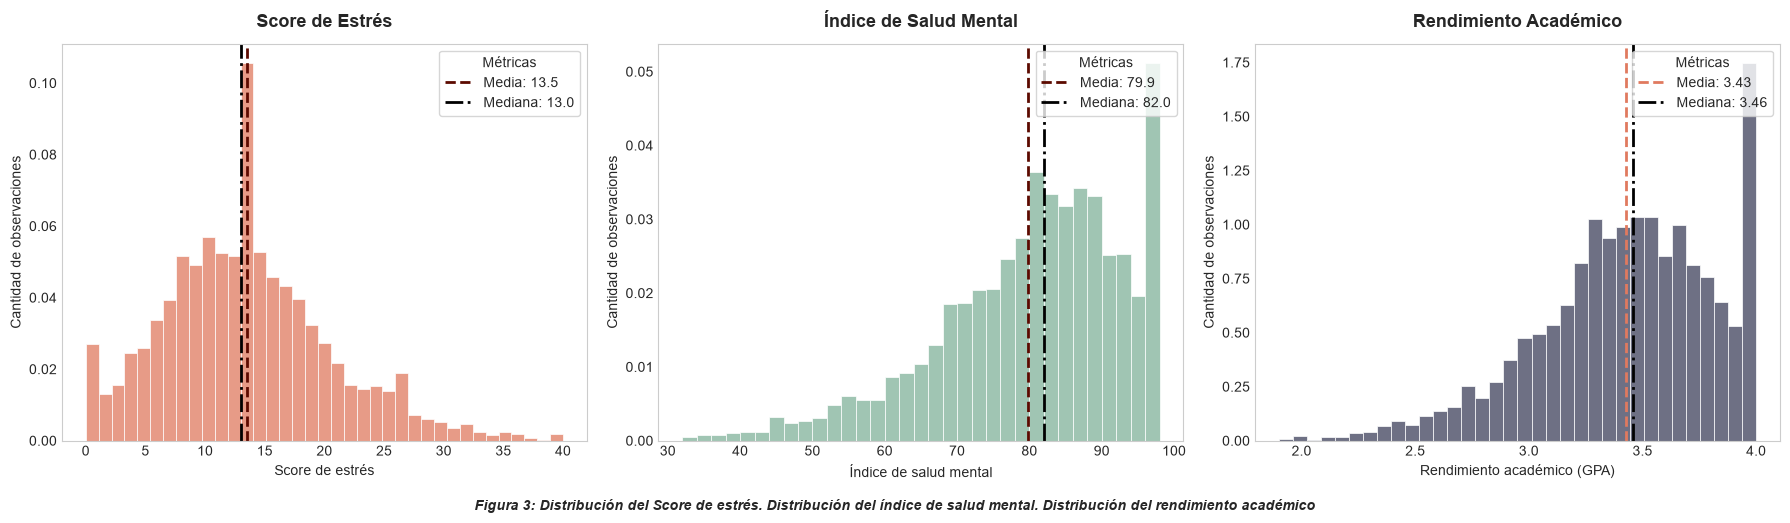

In [141]:
# Crear una figura con tres espacios uno al lado del otro
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5))

# Estrés
media_estres = redes["Perceived_Stress_Score"].mean()
mediana_estres = redes["Perceived_Stress_Score"].median()

sns.histplot(
    data=redes,
    x="Perceived_Stress_Score",
    ax=ax1,
    color="#e07a5f",  
    edgecolor="white",
    linewidth=0.5,
    stat = "density", # Para tener la densidad y no los conteos
)

ax1.axvline(
    media_estres,
    color="#5c0a00",
    linestyle="--",
    linewidth=2,
    label=f"Media: {media_estres:.1f}",
)
ax1.axvline(
    mediana_estres,
    color="#000000",
    linestyle="-.",
    linewidth=2,
    label=f"Mediana: {mediana_estres:.1f}",
)

ax1.set_title("Score de Estrés")
ax1.set_xlabel("Score de estrés")
ax1.set_ylabel("Cantidad de observaciones")
ax1.legend(title="Métricas", frameon=True, loc="upper right")
ax1.grid(False)


# Salud mental
media_salud = redes["Mental_Health_Index"].mean()
mediana_salud = redes["Mental_Health_Index"].median()

sns.histplot(
    data=redes,
    x="Mental_Health_Index",
    ax=ax2,
    color="#81b29a",  
    edgecolor="white",
    linewidth=0.5,
    stat = "density", # Para tener la densidad y no los conteos
)

ax2.axvline(
    media_salud,
    color="#5c0a00",
    linestyle="--",
    linewidth=2,
    label=f"Media: {media_salud:.1f}",
)
ax2.axvline(
    mediana_salud,
    color="#000000",
    linestyle="-.",
    linewidth=2,
    label=f"Mediana: {mediana_salud:.1f}",
)

ax2.set_title("Índice de Salud Mental")
ax2.set_xlabel("Índice de salud mental")
ax2.set_ylabel("Cantidad de observaciones")
ax2.legend(title="Métricas", frameon=True, loc="upper right")
ax2.grid(False)


# Rendimiento académico
media_academico = redes["Academic_Performance_GPA"].mean()
mediana_academico = redes["Academic_Performance_GPA"].median()

sns.histplot(
    data=redes,
    x="Academic_Performance_GPA",
    ax=ax3,
    color="#3d405b",  
    edgecolor="white",
    linewidth=0.5,
    stat = "density", # Para tener la densidad y no los conteos
)

ax3.axvline(
    media_academico,
    color="#e07a5f",
    linestyle="--",
    linewidth=2,
    label=f"Media: {media_academico:.2f}",
)
ax3.axvline(
    mediana_academico,
    color="#000000",
    linestyle="-.",
    linewidth=2,
    label=f"Mediana: {mediana_academico:.2f}",
)

ax3.set_title("Rendimiento Académico")
ax3.set_xlabel("Rendimiento académico (GPA)")
ax3.set_ylabel("Cantidad de observaciones")
ax3.legend(title="Métricas", frameon=True, loc="upper right")
ax3.grid(False)

# Etiqueta para el informe
fig.text(
    0.5,
    -0.03,
    "Figura 3: Distribución del Score de estrés. Distribución del índice de salud mental. Distribución del rendimiento académico",
    ha="center",
    fontsize=10,
    style="italic",
    weight="semibold",
)

# Ajustar diseño general para que respiren los títulos y leyendas
plt.tight_layout()
plt.show()

Se observa como el promedio de calificaciones obtenido por estudiante evidencia una marcada relación negativa frente al promedio de uso diario de las redes sociales; en tanto aumente su uso es esperable visualizar una performance académica más pobre. Esta relación se mantiene independiente del nivel de académico que posea el encuestado. Este gráfico refuerza el coeficiente negativo que se obtuvo entre "Uso diario" y "Rendimiento académico", únicamente que extendiendolo a cada uno de los niveles educativos disponibles, sin mostrar desviaciones en el comportamiento particular del general.

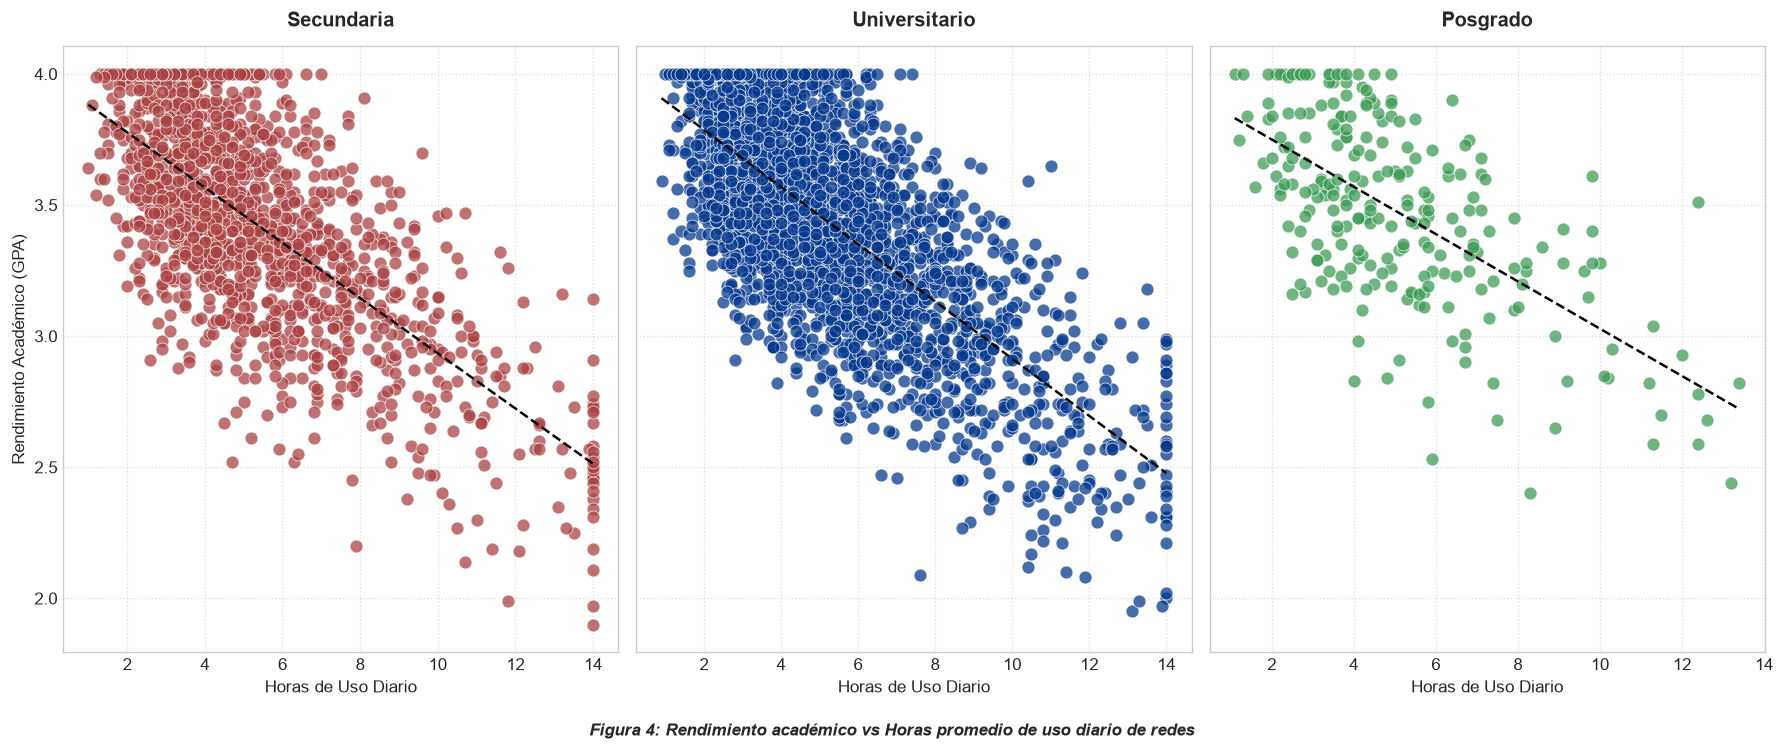

In [ ]:
# Obtener categorías únicas
academic_levels = ["Secundaria", "Universitario", "Posgrado"]

# Colores educación
colores_educ =  ["#ab4242", "#05398e", "#3d9d55"]

# Crear la figura con subplots en una fila (uno por cada nivel académico)
fig, axes = plt.subplots(1, len(academic_levels), figsize=(15, 6), sharey=True)

for i, level in enumerate(academic_levels):

    ax = axes[i]
    subset_academic = redes[redes["Academic_Level"] == level]

    # Dividimos el dataset según nivel académico
    subset_academic = redes[redes["Academic_Level"] == level]

    ax.scatter(
        subset_academic["Daily_Usage_Hours"],
        subset_academic["Academic_Performance_GPA"],
        color = colores_educ[i],
        alpha=0.75,
        s=60,
        edgecolors="w",
        linewidth=0.5
    )
            
    # Linea de mínimos cuadrados. Eliminamos datos faltantes
    min_cuad = subset_academic[["Daily_Usage_Hours", "Academic_Performance_GPA"]].dropna()

    x = min_cuad["Daily_Usage_Hours"]
    y = min_cuad["Academic_Performance_GPA"]

    m, b = np.polyfit(x, y, 1)
    
    m, b = np.polyfit(x, y, 1)
    x_line = np.linspace(x.min(), x.max(), 100)
    y_line = m * x_line + b
    ax.plot(
        x_line, y_line, 
        color="black", 
        linestyle="--", 
        linewidth=1.5, 
        label="Tendencia"
    )

    # Configuración de ejes y títulos de cada panel
    ax.set_title(f"{level}", fontsize=12, weight="bold")
    ax.set_xlabel("Horas de Uso Diario", fontsize=10)
    if ax == axes[0]:
        ax.set_ylabel("Rendimiento Académico (GPA)", fontsize=10)
    ax.grid(True, linestyle=":", alpha=0.6)

# Etiqueta para el informe
fig.text(
    0.5,
    -0.03,
    "Figura 4: Rendimiento académico vs Horas promedio de uso diario de redes",
    ha="center",
    fontsize=10,
    style="italic",
    weight="semibold",
)

plt.tight_layout()
plt.show()

La definición de red social principal es bastante estable a través de cada género o nivel educativo. Se destaca un predominio de Instagram, con una cantidad aproximada del 31-33% del uso total. Este porcentaje se hace algo más grande para ciertas minorías que tienen un uso más intensivo de la red social, aproximandose al 37-38% del uso total. Este crecimiento se da netamente a partir de una disminución del uso en Tik Tok, que es la segunda red social más utilizada. También presentan un uso algo más intenso del Snapchat. Para el resto de los cruces, la red social que completa el podio es Youtube, superando el uso de Snapchat. El resto de redes sociales tiene porcentajes marginales.

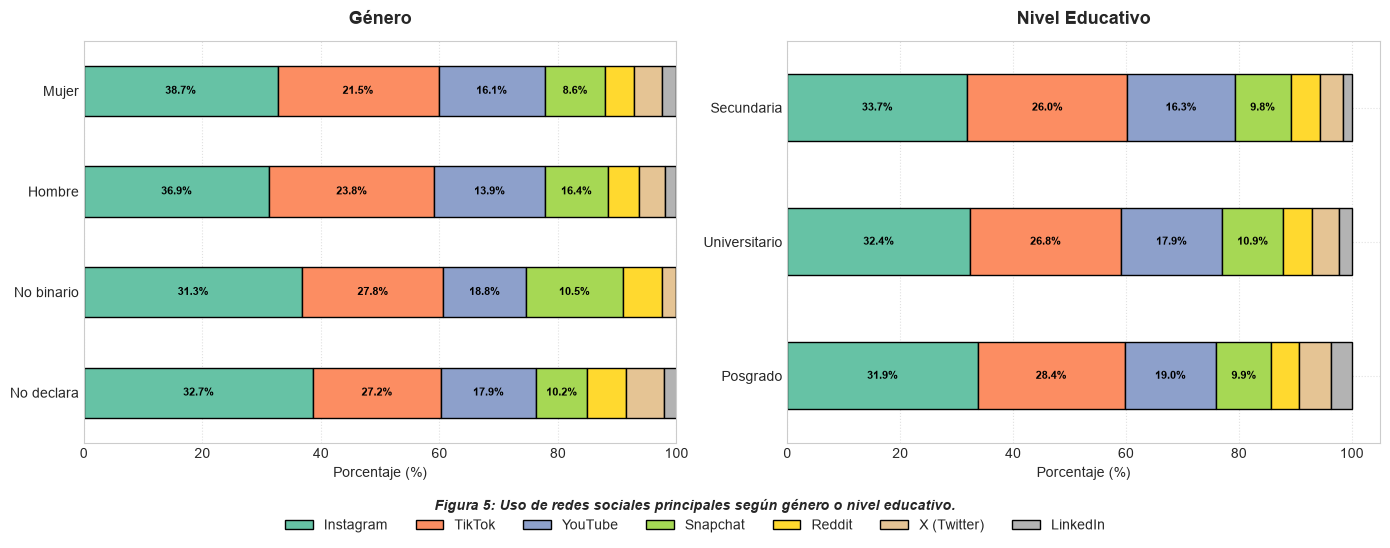

In [143]:
# Tablas cruzadas de proporciones
# crosstab nos da las proporciones entre 0 a 1 de las intersecciones entre los valores de dos columnas
tabla_genero = (
    pd.crosstab(redes["Gender"], redes["Primary_Platform"], normalize="index") * 100
)
tabla_academico = (
    pd.crosstab(redes["Academic_Level"], redes["Primary_Platform"], normalize="index") * 100
)

# Ordenar plataformas de mayor a menor uso general
# Estamos ordenando medias de variables binarias, es decir proporciones
plataformas_ordenadas = tabla_genero.mean().sort_values(ascending=False).index
tabla_genero = tabla_genero[plataformas_ordenadas]
tabla_academico = tabla_academico[plataformas_ordenadas]

# Ordenar las filas de las categorías
tabla_genero = tabla_genero.reindex(["Mujer", "Hombre", "No binario", "No declara"])
tabla_academico = tabla_academico.reindex(["Secundaria", "Universitario", "Posgrado"])

# Dos gráficos uno al lado del otro
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: 
tabla_genero.iloc[::-1].plot(
    kind="barh", stacked=True, ax=ax1, colormap="Set2", edgecolor="black" # El .iloc[::-1] hace que el primero aparezca arriba)
)
ax1.set_title("Género")
ax1.set_xlabel("Porcentaje (%)")
ax1.set_ylabel("")
ax1.legend().set_visible(False) # Quitamos la leyenda de las refernecias para unificar ambos en una

# Gráfico 2: Nivel Educativo
tabla_academico.iloc[::-1].plot(
    kind="barh", stacked=True, ax=ax2, colormap="Set2", edgecolor="black"
)
ax2.set_title("Nivel Educativo")
ax2.set_xlabel("Porcentaje (%)")
ax2.set_ylabel("")
ax2.legend().set_visible(False) # Quitamos la leyenda de las refernecias para unificar ambos en una

# Etiquetas para las proporciones
for ax, df_plot in zip([ax1, ax2], [tabla_genero, tabla_academico]):
  for i, columna in enumerate(df_plot.columns[:4]):
    valores = df_plot[columna]
    # Crear lista de etiquetas (vacía si el valor es 0)
    etiquetas = [f"{v:.1f}%" if v > 0 else "" for v in valores]
    ax.bar_label(
        ax.containers[i],
        labels=etiquetas,
        label_type="center",
        fontsize=8,
        color="black",
        weight="bold",
    )

# Leyenda única y unificada abajo
handles, labels = ax2.get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.10),
    ncol=len(plataformas_ordenadas),
    frameon=False,
)

# Etiqueta para el informe
fig.text(
    0.5,
    -0.03,
    "Figura 5: Uso de redes sociales principales según género o nivel educativo.",
    ha="center",
    fontsize=10,
    style="italic",
    weight="semibold",
)

plt.tight_layout()
plt.show()

### Uso diario de redes sociales y duración del sueño

Se analiza la relación entre las horas diarias de uso de redes sociales (`Daily_Usage_Hours`) y las horas de sueño (`Sleep_Duration_Hours`). Cada punto representa un estudiante; la recta resume la tendencia lineal. La variable de uso corresponde a redes sociales y no al tiempo total de uso del celular.


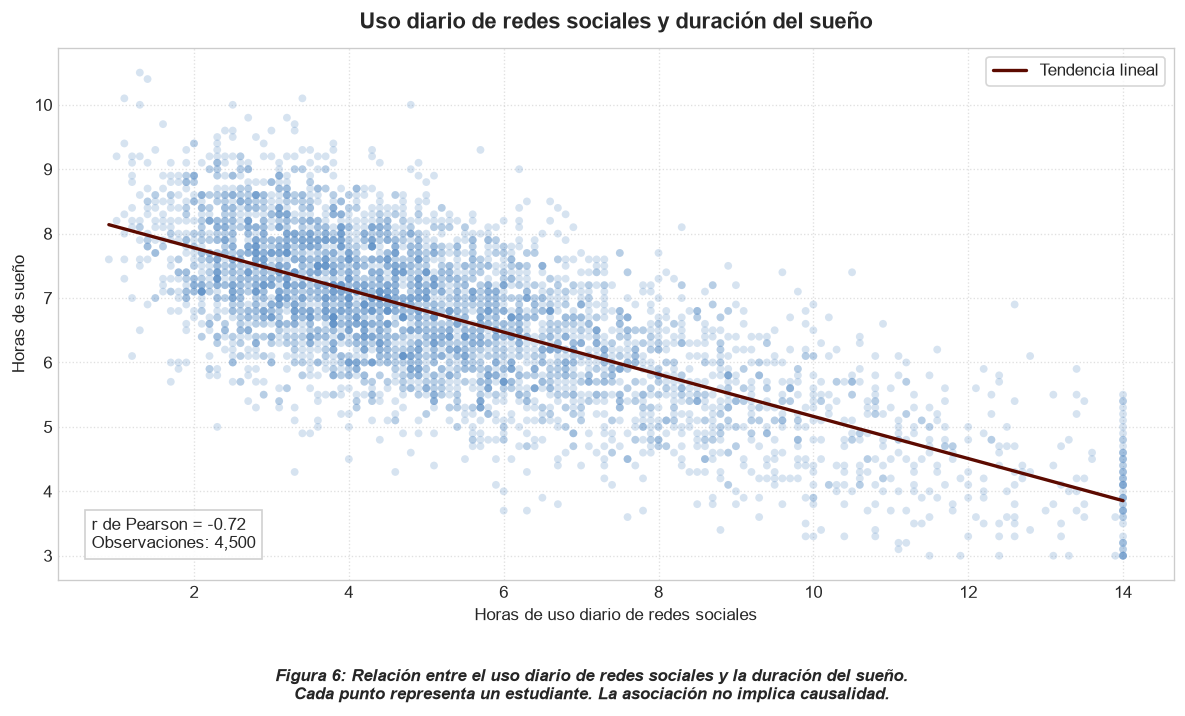

In [ ]:
# Relación entre el uso diario de redes sociales y las horas de sueño
uso_sueno = redes[["Daily_Usage_Hours", "Sleep_Duration_Hours"]].dropna()
r_uso_sueno = uso_sueno["Daily_Usage_Hours"].corr(uso_sueno["Sleep_Duration_Hours"])

fig, ax = plt.subplots(figsize=(10, 6))

sns.regplot(
    data=uso_sueno,
    x="Daily_Usage_Hours",
    y="Sleep_Duration_Hours",
    ax=ax,
    ci=None,
    scatter_kws={"color": "#5d90c7", "alpha": 0.25, "s": 22, "edgecolors": "none"},
    line_kws={"color": "#5c0a00", "linewidth": 2, "label": "Tendencia lineal"},
)

ax.set_title("Uso diario de redes sociales y duración del sueño")
ax.set_xlabel("Horas de uso diario de redes sociales")
ax.set_ylabel("Horas de sueño")
ax.legend(loc="upper right", frameon=True)
ax.text(
    0.03, 0.06,
    f"r de Pearson = {r_uso_sueno:.2f}\nObservaciones: {len(uso_sueno):,}",
    transform=ax.transAxes,
    fontsize=10,
    bbox={"facecolor": "white", "edgecolor": "#cccccc", "alpha": 0.9},
)
ax.grid(True, linestyle=":", alpha=0.6)

fig.text(
    0.5, 0.02,
    "Figura 6: Relación entre el uso diario de redes sociales y la duración del sueño.\n"
    "Cada punto representa un estudiante. La asociación no implica causalidad.",
    ha="center", fontsize=10, style="italic", weight="semibold",
)
plt.tight_layout(rect=[0, 0.10, 1, 1])
plt.show()


Por otro lado, se estudió la vinculación entre las variables referentes al sueño del estudiante. La distribución obtenida respalda la correlación positiva ente la cantidad de horas de sueño y la calidad del mismo. Al discriminar este resultado según el uso nocturno de las redes sociales, no se observan diferencias notorias entre las mismas. No obstante, sistemáticamente la mediana de aquellos que no tiene el hábito se posiciona por encima de aquellos que si en los niveles más bajos de calidad del sueño, y que conforme aumenta la misma, se invierten los roles. En pocas palabras quienes duermen peor pero no utilizan las redes a la noche, tienden a dormir algo más. Esta relación se invierte, haciendo que el que duerme mejor y no hacen uso de las redes, tienden a dormir algo menos. Si bien esta relación se visualiza, no es algo muy marcado. 

Complementando con indicadores de dispersión, se tiene que a nivel general la varianza en las horas de sueño de aquellos que utiilizan las redes sociales es algo mayor. Este fenómeno es constante (salvo para el nivel más bajo de sueño donde se invierten los roles) pero no muy marcado. Si bien podemos observar distinciones entre quienes utilizan o no redes sociales previo a dormir, las diferencias en las horas de sueño no son concluyentes.

Por otro lado, si observamos el segundo gráfico, vemos como aquellos que usan las redes sociales durante la noche, tienen mayor cantidad relativa de calificaciones de sueño en 1 o 2; puntajes bajos. Por otro lado, la concentración de las personas que no utilizan redes previo a dormir, es en torno a valores más altos, con más de la mitad de las calificaciones con valores de 3 o más.

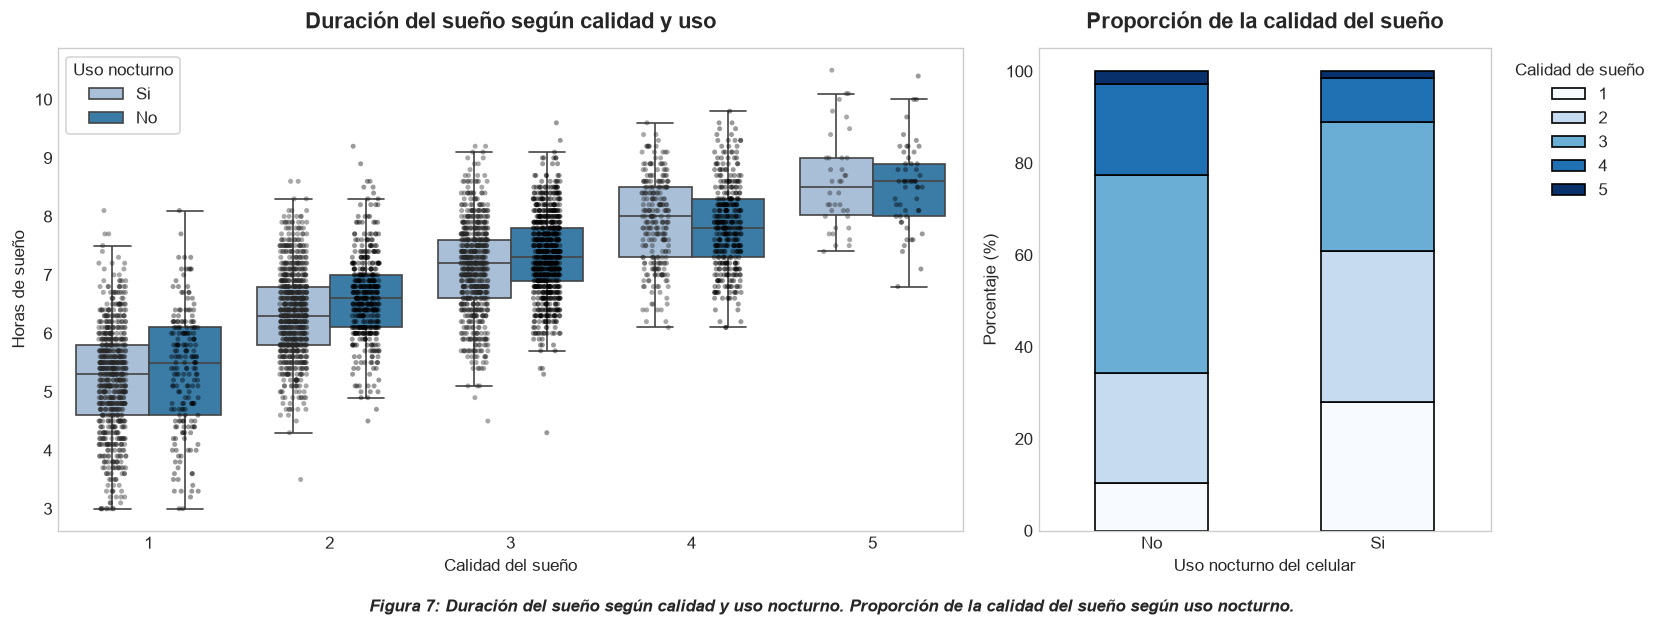

In [ ]:
# Crear una figura con dos espacios (uno para cada gráfico)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [2, 1]})

colores_cajas = ["#a0bfdf", "#2980b9"]

# Boxplot
sns.boxplot(
    data=redes,
    x="Sleep_Quality_Score",
    y="Sleep_Duration_Hours",
    hue="Late_Night_Usage",
    ax=ax1,
    palette= colores_cajas,
    showfliers=False,
)

# Jitter con los puntos
sns.stripplot(
    data=redes,
    x="Sleep_Quality_Score",
    y="Sleep_Duration_Hours",
    hue="Late_Night_Usage",
    ax=ax1,
    dodge=True,
    palette= "dark:black",
    alpha=0.4,
    size=3,
    jitter=0.15,
    legend=False,
)

ax1.set_title("Duración del sueño según calidad y uso")
ax1.set_xlabel("Calidad del sueño")
ax1.set_ylabel("Horas de sueño")
ax1.legend(title="Uso nocturno", frameon=True)
ax1.grid(False)


# Proporciones de calidad del sueño 
prop = (
    pd.crosstab(
        redes["Late_Night_Usage"],
        redes["Sleep_Quality_Score"],
        normalize="index",
    )
    * 100
)

prop.plot(
    kind="bar", stacked=True, ax=ax2, colormap="Blues", edgecolor="black"
)

ax2.set_title("Proporción de la calidad del sueño")
ax2.set_xlabel("Uso nocturno del celular")
ax2.set_ylabel("Porcentaje (%)")
ax2.legend(title="Calidad de sueño", bbox_to_anchor=(1.02, 1), loc="upper left")
ax2.tick_params(axis="x", rotation=0)
ax2.grid(False)

# Etiqueta para el informe
fig.text(
    0.5,
    -0.03,
    "Figura 7: Duración del sueño según calidad y uso nocturno. Proporción de la calidad del sueño según uso nocturno.",
    ha="center",
    fontsize=10,
    style="italic",
    weight="semibold",
)

# Mostrar ambos gráficos ordenados
plt.tight_layout()
plt.show()

In [146]:
# Tabla de resumen de datos sobre el sueño
resumen_sueño = (
    redes.groupby(["Late_Night_Usage", "Sleep_Quality_Score"])["Sleep_Duration_Hours"]
    .agg(Mediana="median", Varianza="var")
    .sort_values(by=["Sleep_Quality_Score", "Varianza"], ascending=False).round(3)
).rename_axis(
        index={
            "Late_Night_Usage": "Uso nocturno",
            "Sleep_Quality_Score": "Calidad del sueño",
        }
    )

# Estético para el informe
display(
    resumen_sueño.style.set_caption(
        "Indicadores de la duración del sueño según uso nocturno"
    )
    .set_properties(**{"text-align": "left", "padding": "6px 12px"})
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#2c3e50"),
                ("color", "white"),
                ("font-weight", "bold"),
                ("text-align", "left"),
            ],
        },
        {"selector": "tr:nth-child(even)", "props": [("background-color", "#f9f9f9")]},
        {"selector": "tr:hover", "props": [("background-color", "#f1f1f1")]},
    ])
)

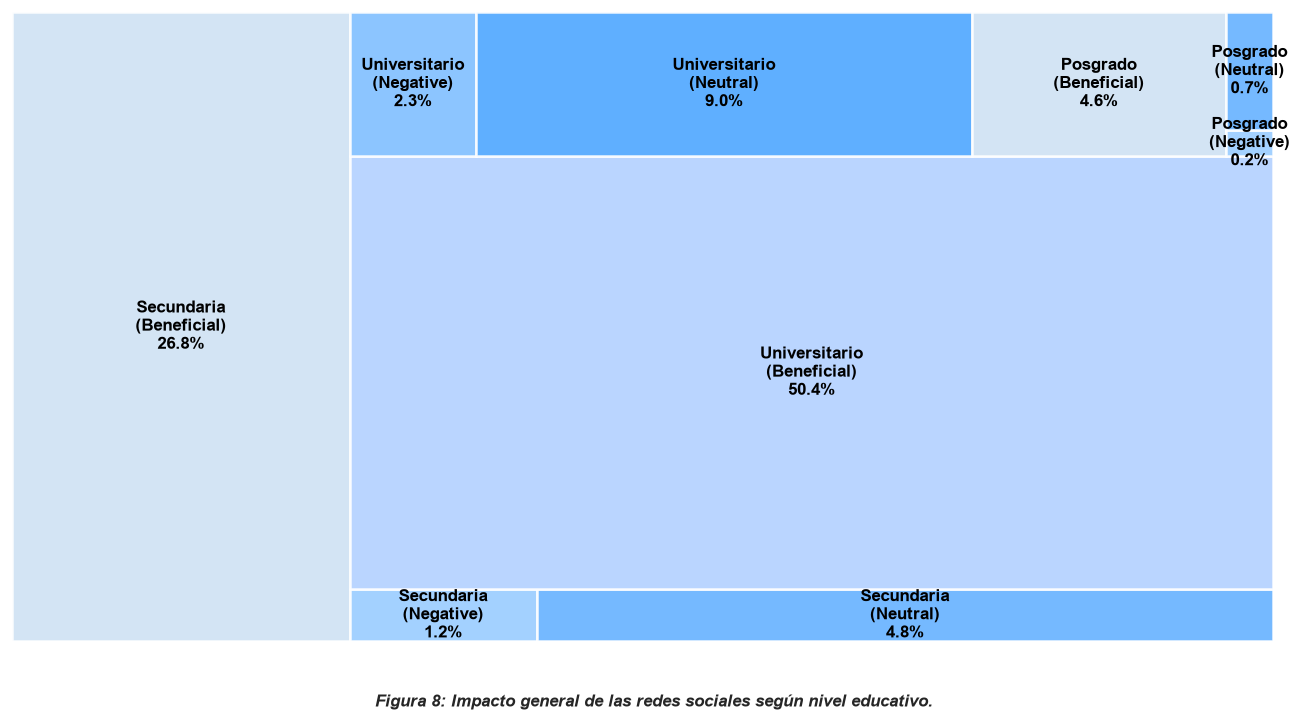

In [ ]:
# Agrupamos las combinaciones de datos Nivel educativo - Impacto
df_tree = (
    redes.groupby(["Academic_Level", "Overall_Impact"])
    .size()
    .reset_index(name="Cantidad")
)

# Procentaje de cada rectángulo
total = df_tree["Cantidad"].sum()
df_tree["Porcentaje"] = (df_tree["Cantidad"] / total) * 100

# 3. Crear las etiquetas con la información ordenada
etiquetas = (
    df_tree["Academic_Level"].astype(str)
    + "\n("
    + df_tree["Overall_Impact"].astype(str)
    + ")\n"
    + df_tree["Porcentaje"].round(1).astype(str)
    + "%"
)

# Paleta
colores = ["#cfe2f3", "#99ccff", "#66b2ff", "#b3d1ff", "#80bfff", "#4da6ff"]

# Grafico de mapa de árbol de la librería squarify
fig = plt.figure(figsize=(11, 6))

squarify.plot(
    sizes=df_tree["Cantidad"],
    label=etiquetas,
    color=colores[: len(df_tree)],
    alpha=0.9,
    edgecolor="white",
    linewidth=1.5,
    text_kwargs={
        "fontsize": 10,
        "color": "black",
        "weight": "bold",
    },  # Texto nítido y en negrita
)

# Etiqueta para el informe
fig.text(
    0.5,
    0.01,
    "Figura 8: Impacto general de las redes sociales según nivel educativo.",
    ha="center",
    fontsize=10,
    style="italic",
    weight="semibold",
)

plt.axis("off")
plt.tight_layout(rect=[0, 0.07, 1, 1])
plt.show()

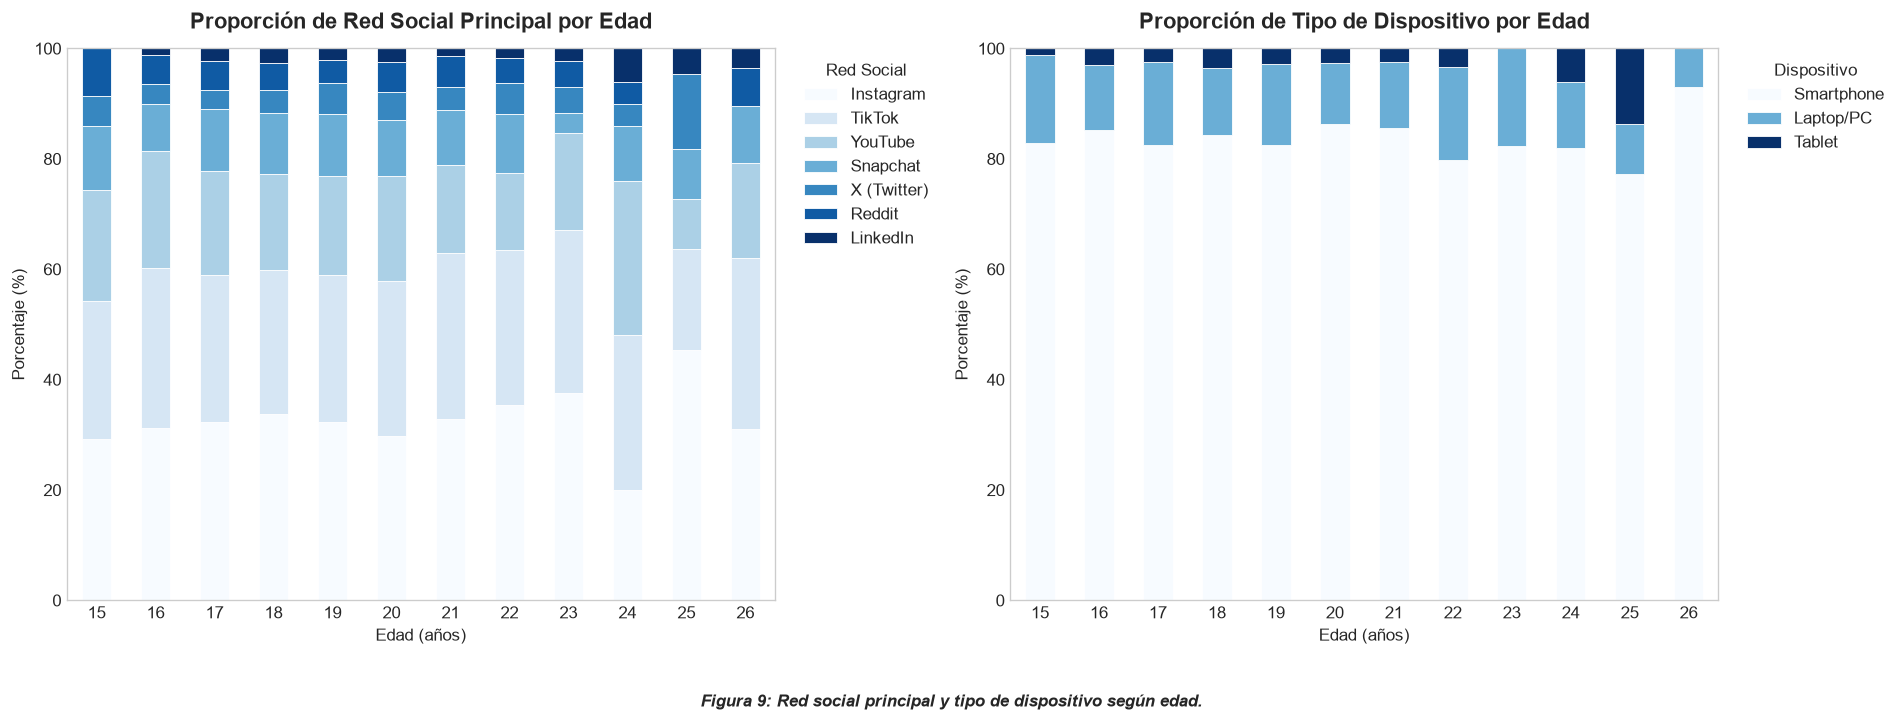

In [ ]:
# 1. Asegurar formato numérico para la edad y limpiar valores nulos
redes["Age"] = pd.to_numeric(redes["Age"], errors="coerce")
datos_limpios = redes.dropna(subset=["Age", "Primary_Platform", "Device_Type"])

# 2. Crear una figura con dos espacios uno al lado del otro
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# --- GRÁFICO 1: Edad vs Red Social Principal (Ordenado de mayor a menor proporción abajo) ---
ct1 = (
    pd.crosstab(
        datos_limpios["Age"],
        datos_limpios["Primary_Platform"],
        normalize="index",
    )
    * 100
)
# Ordenar las columnas de mayor a menor total para que la categoría mayor quede abajo
ct1 = ct1[ct1.sum().sort_values(ascending=False).index]

ct1.plot(
    kind="bar",
    stacked=True,
    ax=ax1,
    colormap="Blues",
    edgecolor="white",
    linewidth=0.5,
)

ax1.set_title("Proporción de Red Social Principal por Edad")
ax1.set_xlabel("Edad (años)")
ax1.set_ylabel("Porcentaje (%)")
ax1.legend(title="Red Social", bbox_to_anchor=(1.02, 1), loc="upper left")
ax1.grid(False)
ax1.set_xticklabels(ax1.get_xticklabels(), rotation=0)


# --- GRÁFICO 2: Edad vs Tipo de Dispositivo (Ordenado de mayor a menor proporción abajo) ---
ct2 = (
    pd.crosstab(
        datos_limpios["Age"], datos_limpios["Device_Type"], normalize="index"
    )
    * 100
)
# Ordenar las columnas de mayor a menor total
ct2 = ct2[ct2.sum().sort_values(ascending=False).index]

ct2.plot(
    kind="bar",
    stacked=True,
    ax=ax2,
    colormap="Blues",
    edgecolor="white",
    linewidth=0.5,
)

ax2.set_title("Proporción de Tipo de Dispositivo por Edad")
ax2.set_xlabel("Edad (años)")
ax2.set_ylabel("Porcentaje (%)")
ax2.legend(title="Dispositivo", bbox_to_anchor=(1.02, 1), loc="upper left")
ax2.grid(False)
ax2.set_xticklabels(ax2.get_xticklabels(), rotation=0)


# Ajustar diseño general para que las leyendas respiren
# Etiqueta para el informe
fig.text(
    0.5, 0.01,
    'Figura 9: Red social principal y tipo de dispositivo según edad.',
    ha="center", fontsize=10, style="italic", weight="semibold",
)

plt.tight_layout(rect=[0, 0.07, 1, 1])
plt.show()

La distribución de la red social principal presenta un patrón relativamente estable entre los 15 y los 26 años: Instagram concentra la mayor proporción de estudiantes, seguida por TikTok y YouTube. No se observa una tendencia sostenida de aumento o disminución de estas preferencias con la edad. Además, los porcentajes representan la proporción de estudiantes que eligen cada plataforma como principal, no el tiempo que dedican a utilizarla.

El uso de celular predomina de manera amplia para todas las edades. 

<a id="modelado"></a>
## Modelado predictivo  

Se pretenden predecir el índice de salud mental como variable objetivo. 

Se excluyen identificador, `Overall_Impact`, estrés y el otro resultado de bienestar/rendimiento.

**MAE** es el error absoluto medio en unidades del objetivo; menor es mejor. 

**RMSE** da más peso a errores grandes.

 **R²** compara el error cuadrático con la variabilidad observada; puede ser negativo. 
 
 No se comparan MAE de salud mental y GPA entre sí, porque tienen escalas diferentes.



In [149]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

objetivo = "Mental_Health_Index"

variables = [
    "Age", "Daily_Usage_Hours", "Weekend_Extra_Hours",
    "Sleep_Duration_Hours", "Sleep_Quality_Score",
    "Gender", "Academic_Level", "Late_Night_Usage",
    "Social_Comparison_Frequency",
]

# Quitamos faltantes y convertimos las categorías en columnas numéricas
base = redes.dropna(subset=variables + [objetivo])
X = pd.get_dummies(base[variables], drop_first=True)
y = base[objetivo]

# Mismos datos de entrenamiento y prueba para los tres modelos
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

def evaluar(modelo):
    pred = modelo.predict(X_test)
    print(f"MAE:  {mean_absolute_error(y_test, pred):.3f}")
    print(f"RMSE: {root_mean_squared_error(y_test, pred):.3f}")
    print(f"R²:   {r2_score(y_test, pred):.3f}")

In [150]:
# Arbol de decisión
arbol = DecisionTreeRegressor(max_depth=3, random_state=42)

arbol.fit(X_train, y_train)
evaluar(arbol)

MAE:  5.383
RMSE: 6.635
R²:   0.723


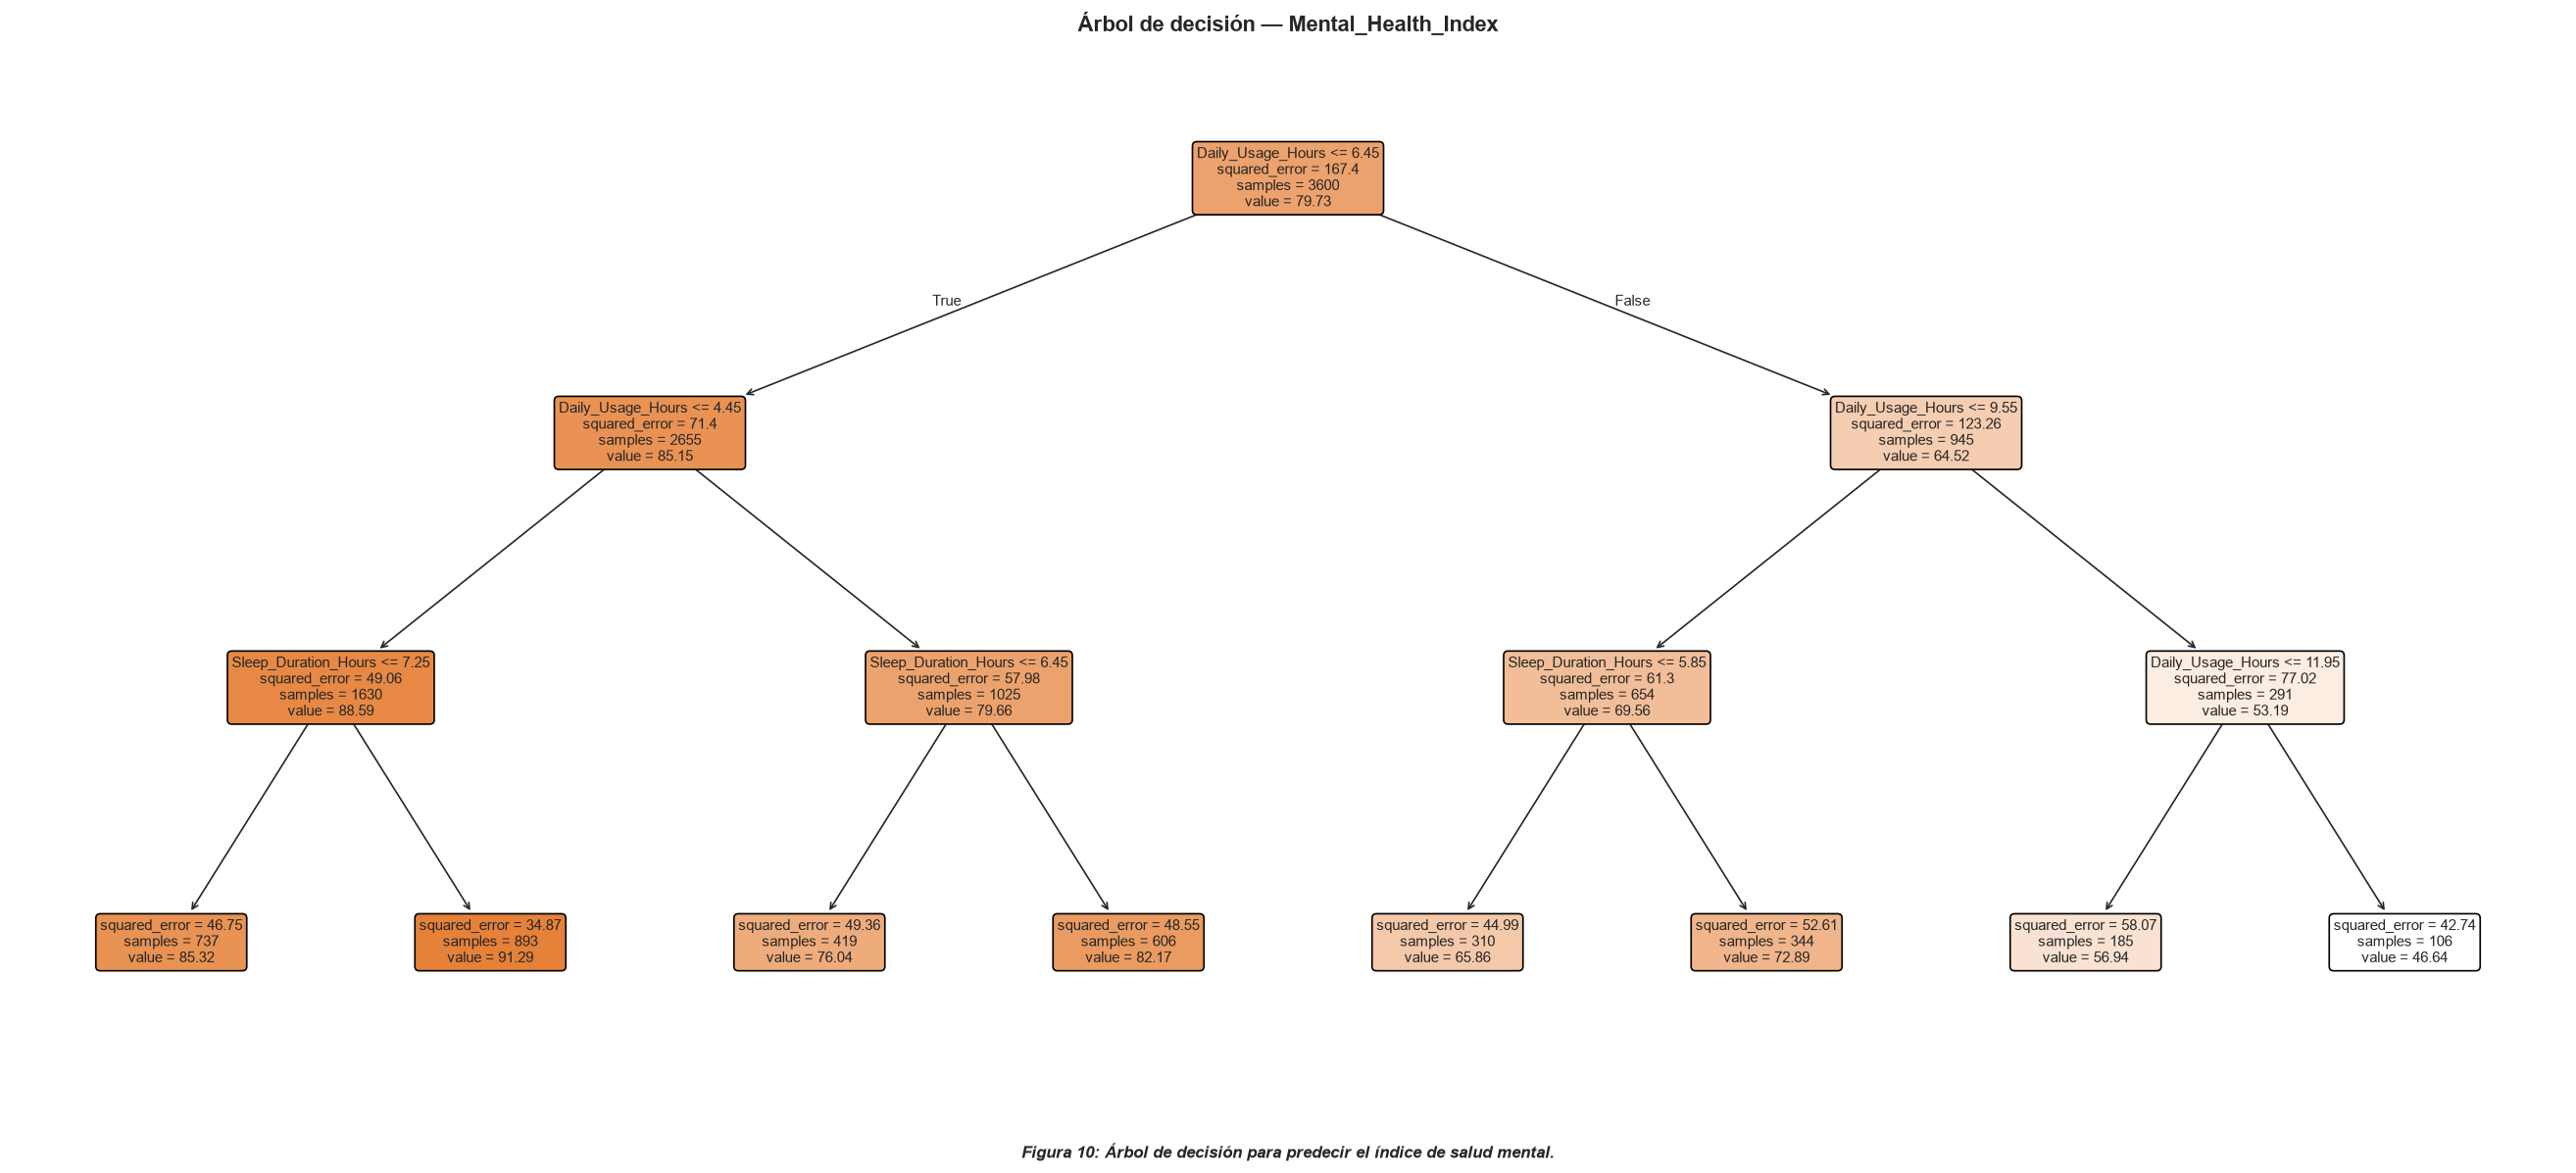

In [ ]:
from sklearn.tree import plot_tree

fig, ax = plt.subplots(figsize=(22, 10))

plot_tree(
    arbol,
    feature_names=X_train.columns.tolist(),
    filled=True,
    rounded=True,
    precision=2,
    fontsize=9,
    ax=ax,
)

ax.set_title(f"Árbol de decisión — {objetivo}")
# Etiqueta para el informe
fig.text(
    0.5, 0.01,
    'Figura 10: Árbol de decisión para predecir el índice de salud mental.',
    ha="center", fontsize=10, style="italic", weight="semibold",
)

plt.tight_layout(rect=[0, 0.07, 1, 1])
plt.show()

El primer predictor que utliza este árbol son las horas de uso diario, variable que se utiliza dos veces para separar el dataframe en dos, es decir, el modelo identifica como relevante para predecir el índice de salud mental a las horas de de uso diario. Luego, vuelve a dividir por esta variable, por lo que en definitiva este árbol termina dividiendo en 4 por las horas de uso. Luego, en casi todos los casos divide por las horas de sueño a excepción de un caso que divide nuevamente por horas de uso de celular. 

In [152]:
bosques = {
    "Bosque simple": RandomForestRegressor(
        n_estimators=100, max_depth=3, random_state=42
    ),
    "Bosque intermedio": RandomForestRegressor(
        n_estimators=100, max_depth=6, random_state=42
    ),
    "Bosque sin límite": RandomForestRegressor(
        n_estimators=100, max_depth=None, random_state=42
    ),
}

resultados = []

for nombre, modelo in bosques.items():
    modelo.fit(X_train, y_train)

    pred_train = modelo.predict(X_train)
    pred_test = modelo.predict(X_test)

    resultados.append({
        "Modelo": nombre,
        "MAE train": mean_absolute_error(y_train, pred_train),
        "MAE test": mean_absolute_error(y_test, pred_test),
        "RMSE train": root_mean_squared_error(y_train, pred_train),
        "RMSE test": root_mean_squared_error(y_test, pred_test),
        "R² train": r2_score(y_train, pred_train),
        "R² test": r2_score(y_test, pred_test),
    })

comparacion = pd.DataFrame(resultados).set_index("Modelo")
display(comparacion.sort_values("RMSE test").round(3))

,MAE train,MAE test,RMSE train,RMSE test,R² train,R² test
Modelo,,,,,,
Bosque intermedio,4.563,4.854,5.699,6.047,0.806,0.770
Bosque simple,5.120,5.128,6.354,6.344,0.759,0.747
Bosque sin límite,1.911,5.107,2.415,6.420,0.965,0.740


El bosque intermedio (max_depth=6) obtiene el mejor desempeño en test, con menores valores de MAE y RMSE y un mayor R². Aún así, presenta un leve sobreajuste observable en la caída entre train y test. 

El bosque simple presenta un menor ajuste, mientras que el bosque sin límite muestra sobreajuste: su R² pasa de 0,965 en train a 0,740 en test. Por lo tanto, el bosque intermedio logra el mejor equilibrio entre ajuste y capacidad de generalización para predecir el índice de salud mental.

,Importancia (%)
Daily_Usage_Hours,88.34
Sleep_Duration_Hours,9.95
Weekend_Extra_Hours,0.70
Age,0.29
Social_Comparison_Frequency_Rarely,0.12
Late_Night_Usage_Si,0.10
Gender_No declara,0.09
Sleep_Quality_Score,0.09
Social_Comparison_Frequency_Never,0.07
Gender_Hombre,0.05


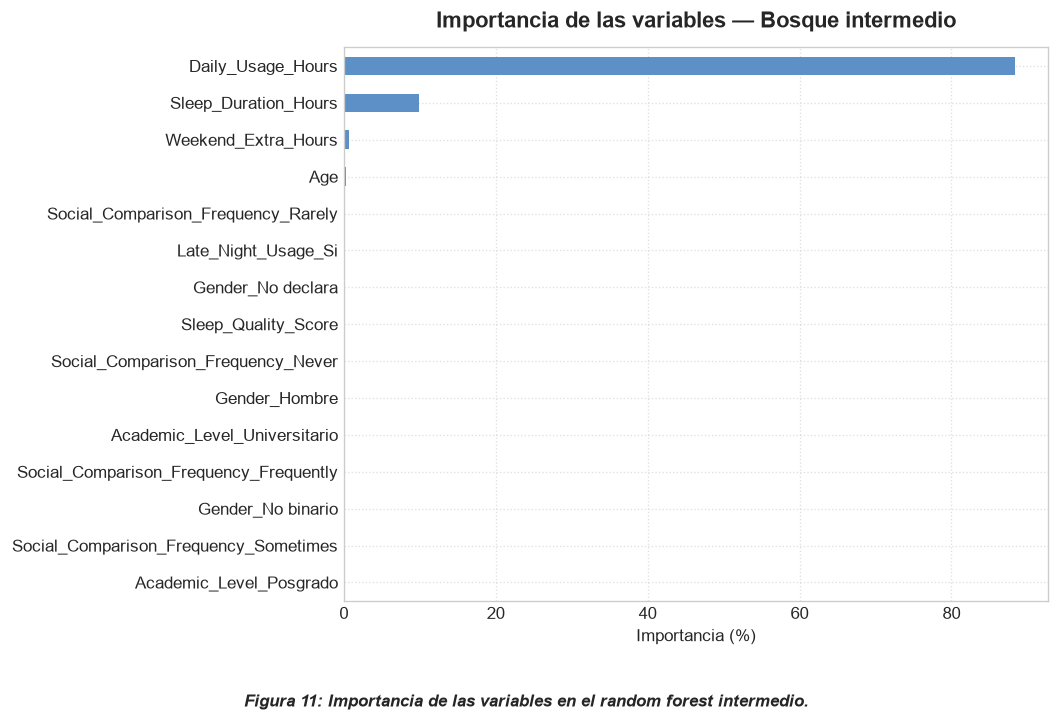

In [ ]:
importancias = pd.Series(
    bosques["Bosque intermedio"].feature_importances_,
    index=X_train.columns,
).sort_values(ascending=False)

display((importancias * 100).round(2).to_frame("Importancia (%)"))

# Gráfico
fig, ax = plt.subplots(figsize=(9, 6))

(importancias * 100).sort_values().plot.barh(
    ax=ax,
    color="#5d90c7",
)

ax.set_title("Importancia de las variables — Bosque intermedio")
ax.set_xlabel("Importancia (%)")
ax.set_ylabel("")

# Etiqueta para el informe
fig.text(
    0.5, 0.01,
    'Figura 11: Importancia de las variables en el random forest intermedio.',
    ha="center", fontsize=10, style="italic", weight="semibold",
)

plt.tight_layout(rect=[0, 0.07, 1, 1])
plt.show()

El uso diario concentra la mayor parte de la capacidad predictiva del modelo. 

Lo compararemos contra el mismo modelo sin dicha variable:

In [154]:
X_train_sin_uso = X_train.drop(columns="Daily_Usage_Hours")
X_test_sin_uso = X_test.drop(columns="Daily_Usage_Hours")

bosque_sin_uso = RandomForestRegressor(
    n_estimators=100, max_depth=6, random_state=42
)
bosque_sin_uso.fit(X_train_sin_uso, y_train)

resultados_uso = []

for nombre, modelo, x_train, x_test in [
    ("Con uso diario", bosques["Bosque intermedio"], X_train, X_test),
    ("Sin uso diario", bosque_sin_uso, X_train_sin_uso, X_test_sin_uso),
]:
    fila = {"Modelo": nombre}

    for conjunto, x, y in [
        ("train", x_train, y_train),
        ("test", x_test, y_test),
    ]:
        pred = modelo.predict(x)
        fila[f"MAE {conjunto}"] = mean_absolute_error(y, pred)
        fila[f"RMSE {conjunto}"] = root_mean_squared_error(y, pred)
        fila[f"R² {conjunto}"] = r2_score(y, pred)

    resultados_uso.append(fila)

display(pd.DataFrame(resultados_uso).set_index("Modelo").round(3))

,MAE train,RMSE train,R² train,MAE test,RMSE test,R² test
Modelo,,,,,,
Con uso diario,4.563,5.699,0.806,4.854,6.047,0.770
Sin uso diario,5.800,7.295,0.682,5.887,7.383,0.657


Queda evidenciada la relevancia de la variable uso diario en la caída de rendimiento. 

In [155]:
regresion = LinearRegression()
regresion.fit(X_train, y_train)

resultados_regresion = []

for conjunto, X_datos, y_datos in [
    ("train", X_train, y_train),
    ("test", X_test, y_test),
]:
    pred = regresion.predict(X_datos)

    resultados_regresion.append({
        "Conjunto": conjunto,
        "MAE": mean_absolute_error(y_datos, pred),
        "RMSE": root_mean_squared_error(y_datos, pred),
        "R²": r2_score(y_datos, pred),
    })

display(
    pd.DataFrame(resultados_regresion)
    .set_index("Conjunto")
    .round(3)
)

,MAE,RMSE,R²
Conjunto,,,
train,4.842,6.073,0.780
test,4.749,5.949,0.777


Los resultados obtenidos no denotan sobreajuste, y son sumamente similares a los obtenidos por los random forest. 

In [156]:
modelos = {
    "Regresión lineal": regresion,
    "Bosque intermedio": bosques["Bosque intermedio"],
}

resultados = []

for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    fila = {"Modelo": nombre}

    for conjunto, X_datos, y_datos in [
        ("train", X_train, y_train),
        ("test", X_test, y_test),
    ]:
        pred = modelo.predict(X_datos)

        fila[f"MAE {conjunto}"] = mean_absolute_error(y_datos, pred)
        fila[f"RMSE {conjunto}"] = root_mean_squared_error(y_datos, pred)
        fila[f"R² {conjunto}"] = r2_score(y_datos, pred)

    resultados.append(fila)

comparacion = pd.DataFrame(resultados).set_index("Modelo")
display(comparacion.sort_values("RMSE test").round(3))

,MAE train,RMSE train,R² train,MAE test,RMSE test,R² test
Modelo,,,,,,
Regresión lineal,4.842,6.073,0.780,4.749,5.949,0.777
Bosque intermedio,4.563,5.699,0.806,4.854,6.047,0.770


La regresión lineal presenta un desempeño ligeramente superior en test: obtiene un MAE de 4,749 y un RMSE de 5,949, frente a 4,854 y 6,047 del bosque intermedio. Su R² también es mayor: 0,777 frente a 0,770.
Además, la regresión mantiene un R² prácticamente constante entre train y test —0,780 y 0,777—, mientras que el bosque pasa de 0,806 a 0,770. Esto sugiere que el mejor ajuste del bosque en train no se traduce en mejores predicciones sobre test.



In [157]:
coeficientes = pd.DataFrame({
    "Regresor": X_train.columns,
    "Coeficiente": regresion.coef_,
})

# Ordenamos por magnitud del coeficiente
coeficientes = coeficientes.loc[
    coeficientes["Coeficiente"].abs().sort_values(ascending=False).index
]

display(coeficientes.set_index("Regresor").round(3))
print(f"Intercepto: {regresion.intercept_:.3f}")

,Coeficiente
Regresor,
Sleep_Duration_Hours,3.608
Daily_Usage_Hours,-3.019
Academic_Level_Posgrado,-1.657
Academic_Level_Universitario,-0.969
Social_Comparison_Frequency_Rarely,-0.582
Social_Comparison_Frequency_Never,0.543
Gender_No declara,-0.471
Gender_No binario,-0.311
Social_Comparison_Frequency_Sometimes,-0.282


Intercepto: 69.670


Manteniendo constantes los demás predictores, cada hora adicional de sueño se asocia con 3,608 puntos más en el índice de salud mental, mientras que cada hora adicional de uso diario de redes se asocia con 3,019 puntos menos.

# Conclusiones

El análisis permitió identificar una asociación entre el uso intensivo de redes sociales y menores indicadores de bienestar psicológico, duración y calidad del sueño y rendimiento académico, así como mayores niveles de estrés. La distribución del uso diario presentó una asimetría hacia consumos elevados, mientras que las horas de sueño mostraron una distribución más equilibrada. 

Las horas de uso diario tuvieron un papel relevante a la hora de predecir: al excluir esta variable, el R² en test descendió de 0,770 a 0,657. Sin embargo, los demás predictores conservaron capacidad predictiva, por lo que el índice de salud mental no quedó explicado exclusivamente por el tiempo de uso.

La regresión lineal obtuvo el mejor resultado observado. Sus coeficientes indicaron que, manteniendo constantes las demás variables, una hora adicional de sueño se asoció con 3,608 puntos más en el índice de salud mental, mientras que una hora adicional de uso diario de redes se asoció con 3,019 puntos menos. Estas estimaciones no deben interpretarse como efectos causales ni extrapolarse a toda la población.

Por su simplicidad, interpretabilidad y desempeño, la regresión lineal constituye la alternativa más adecuada entre los modelos evaluados para este informe.